# Step 15 — pregnant women: can a few strong features rescue the pregnant-only model?

In step 14 a model trained on pregnant women only reached a within-cycle AUROC of 0.658 / 0.716 (elastic net / XGBoost), against 0.856 / 0.835 for the general model on the same women. The likely reason is 320–585 training women (28–49 positive) for 317 features. This notebook cuts the features down to a few strong ones and trains on pregnant women only again.

**Where the "strong features" come from** matters, so two ways are compared. Both use the training cycles only, so the test cycle never takes part in the choice.

| selection | how the top k are chosen for a test cycle |
|---|---|
| from the general population | total gain in the general XGBoost model (step 1 parameters) trained on the other 6 cycles, no pregnant women |
| from pregnant women | univariate AUROC, max(a, 1 − a), among the pregnant women of the other 6 cycles (missing set to the median) |

**k** = 3, 5, 10, 20, 50 (and 317 = step 14).

**Models on the top k**, all leave-one-cycle-out as in step 14, tested on the pregnant women of the test cycle:
- *pregnant only:* trained on the pregnant women of the other 6 cycles, hyper-parameters by inner LOCO (elastic net and XGBoost, `nhanes/loco.py`).
- *general, top k* (for the general-population ranking only): the general population of the other 6 cycles with the same k features and step 1's hyper-parameters. This is what those k features can do with enough training people, so the gap to *pregnant only* at the same k is the cost of the small sample, and its gap to the 317-feature general model is the cost of dropping features.

**Evaluation** as in step 14: within-cycle AUROC over the 630 out-of-cycle predictions (pairs compared inside a test cycle only), 95% bootstrap interval, and pooled AUROC.

**Note:** selecting features with the general population already borrows information from it. A pregnant-only model that reaches the general model this way is a transfer result, not evidence that pregnant women can be modelled on their own.

**Output:** `$NHANES_WORK/modeling/step15_pregnant_topk/` with `predictions.csv.gz`, `selected.csv` and `metrics.csv`. `RUN = True` retrains (CPU only); `RUN = False` only reads the saved results.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, WORK  # noqa: E402

RUN = False  # True: retrain and overwrite $NHANES_WORK/modeling/step15_pregnant_topk
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
OUT = RESULTS / "step15_pregnant_topk"
STEP1, STEP14 = RESULTS / "step1", RESULTS / "step14_pregnant"
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
KS = [3, 5, 10, 20, 50]
GENERAL, OWN = "from the general population", "from pregnant women"

## Run

In [2]:
if RUN:
    from nhanes.loco import (FEAT, LOGREG_GRID, NOT_FEATURES, XGB_GRID, fit_logreg, fit_xgb, grid, logreg_matrix,
                             tune)

    OUT.mkdir(parents=True, exist_ok=True)
    main = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    preg = pd.read_csv(WORK / "features_pregnant" / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    feats = [c for c in main if c not in NOT_FEATURES]
    chosen = json.loads((STEP1 / "chosen_params.json").read_text())
    cycles = sorted(main.cycle.unique())
    grids = {"logreg": grid(LOGREG_GRID), "xgboost": grid(XGB_GRID)}

    def fit_predict(model, tr, te, cols, params):
        params = dict(params)
        if model == "logreg":
            A, B = logreg_matrix(tr[cols], te[cols], dic)
            return fit_logreg(A, tr.depression, params).predict_proba(B)[:, 1]
        n = params.pop("n_estimators")
        return fit_xgb(tr[cols], tr.depression, None, None, params, n_estimators=n).predict_proba(te[cols])[:, 1]

    preds, picked = [], []
    for c in cycles:
        g_tr, p_tr, te = main[main.cycle != c], preg[preg.cycle != c], preg[preg.cycle == c]
        train_cycles = [x for x in cycles if x != c]
        step1 = {m: {k: v for k, v in chosen[f"{m}|{c}"].items() if k != "inner_auroc"} for m in NAMES}
        # ranking 1: total gain of the general XGBoost model on the training cycles
        p = dict(step1["xgboost"])
        n = p.pop("n_estimators")
        gain = fit_xgb(g_tr[feats], g_tr.depression, None, None, p, n_estimators=n).get_booster().get_score(
            importance_type="total_gain")
        rank_general = sorted(feats, key=lambda f: -gain.get(f, 0.0))
        # ranking 2: univariate AUROC among the pregnant women of the training cycles
        X = p_tr[feats].fillna(p_tr[feats].median())
        uni = {f: roc_auc_score(p_tr.depression, X[f]) if X[f].nunique() > 1 else 0.5 for f in feats}
        rank_own = sorted(feats, key=lambda f: -abs(uni[f] - 0.5))
        for selection, rank in [(GENERAL, rank_general), (OWN, rank_own)]:
            for k in KS:
                cols = rank[:k]
                picked.append({"test_cycle": c, "selection": selection, "k": k, "features": ", ".join(cols)})
                sub = p_tr[NOT_FEATURES + cols]
                for model in NAMES:
                    params, _ = tune(model, sub, train_cycles, dic, grids[model])
                    preds.append(pd.DataFrame({"SEQN": te.SEQN, "cycle": c, "selection": selection, "k": k,
                                               "training": "pregnant only", "model": model,
                                               "depression": te.depression,
                                               "prob": fit_predict(model, p_tr, te, cols, params)}))
                    if selection == GENERAL:
                        preds.append(pd.DataFrame({"SEQN": te.SEQN, "cycle": c, "selection": selection, "k": k,
                                                   "training": "general, top k", "model": model,
                                                   "depression": te.depression,
                                                   "prob": fit_predict(model, g_tr, te, cols, step1[model])}))
            print(c, selection, "done", flush=True)
    pd.concat(preds, ignore_index=True).to_csv(OUT / "predictions.csv.gz", index=False)
    pd.DataFrame(picked).to_csv(OUT / "selected.csv", index=False)

## Which features are selected

Features in the top 10, and in how many of the 7 folds. A stable selection picks the same features in every fold.

In [3]:
sel = pd.read_csv(OUT / "selected.csv")
dic_all = pd.read_csv(WORK / "features" / "feature_dictionary.csv").set_index("column")
for selection in [GENERAL, OWN]:
    s = sel[(sel.selection == selection) & (sel.k == 10)].features.str.split(", ").explode().value_counts()
    t = pd.DataFrame({"folds (of 7)": s, "meaning": dic_all.rule.reindex(s.index).str.slice(0, 70)})
    print(f"top 10 {selection}: {len(s)} different features over the 7 folds")
    display(t.head(15))

top 10 from the general population: 14 different features over the 7 folds


,folds (of 7),meaning
features,,
HSD010,7,General health condition
SLQ050,7,Ever told doctor had trouble sleeping?
PFQ049,7,Limitations keeping you from working
PFQ057,7,Experience confusion/memory problems
HUQ010,7,General health condition
pf_difficulty_count,7,# of 20 activities with some / much difficulty...
pf_severe_count,6,# with much difficulty or unable
DBQ700,6,How healthy is the diet
sleep_hours,5,"hours of sleep, whole hours, 12 = 12+; NOTE 20..."


top 10 from pregnant women: 17 different features over the 7 folds


,folds (of 7),meaning
features,,
HUQ010,7,General health condition
URXUCR,7,"Creatinine, urine (mg/dL)"
fam_income_cat,7,"1-10 as coded ($0-74,999 in 10 bands), 11 = $7..."
LBXCOT,6,"Cotinine, Serum (ng/mL)"
hh_income_cat,6,as fam_income_cat
DBQ700,6,How healthy is the diet
INDFMPIR,6,Ratio of family income to poverty
RHQ160,5,# pregnancies; never pregnant -> 0; men -1
HSD010,5,General health condition


## Results

In [4]:
def within_cycle_auc(y, p, cycle):
    num = den = 0.0
    for c in np.unique(cycle):
        m = cycle == c
        pairs = y[m].sum() * (1 - y[m]).sum()
        if pairs:
            num += roc_auc_score(y[m], p[m]) * pairs
            den += pairs
    return num / den


def summarise(f, n=2000, seed=42):
    f = f.sort_values("SEQN")
    y, p, c = f.depression.to_numpy(), f.prob.to_numpy(), f.cycle.to_numpy()
    rng = np.random.default_rng(seed)
    bs = []
    while len(bs) < n:
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            bs.append(within_cycle_auc(y[i], p[i], c[i]))
    return {"within-cycle AUROC": within_cycle_auc(y, p, c), "lo": np.percentile(bs, 2.5),
            "hi": np.percentile(bs, 97.5), "pooled AUROC": roc_auc_score(y, p)}


pred = pd.read_csv(OUT / "predictions.csv.gz")
ref = pd.read_csv(STEP14 / "predictions.csv.gz")
rows = [{"selection": s, "k": k, "training": t, "model": NAMES[m], **summarise(f)}
        for (s, k, t, m), f in pred.groupby(["selection", "k", "training", "model"])]
for (t, m), f in ref[ref.training != "general + pregnant"].groupby(["training", "model"]):  # all 317: step 14
    s317 = summarise(f)
    for s in ([GENERAL] if t == "general" else [GENERAL, OWN]):
        rows.append({"selection": s, "k": 317, "training": "general, top k" if t == "general" else t,
                     "model": NAMES[m], **s317})
met = pd.DataFrame(rows)
met.to_csv(OUT / "metrics.csv", index=False)
wide = met.pivot_table(index=["model", "training", "selection"], columns="k", values="within-cycle AUROC")
display(wide.round(3).fillna(""))
best = met[(met.training == "pregnant only") & (met.k < 317)].sort_values("within-cycle AUROC", ascending=False)
display(best.groupby("model").head(3).set_index(["model", "selection", "k"])[["within-cycle AUROC", "lo", "hi",
                                                                             "pooled AUROC"]].round(3))

k                                                         3      5      10   \
model       training       selection                                          
XGBoost     general, top k from the general population  0.701  0.732  0.776   
            pregnant only  from pregnant women          0.636  0.661  0.714   
                           from the general population  0.689  0.673  0.692   
elastic net general, top k from the general population  0.716  0.728  0.776   
            pregnant only  from pregnant women          0.644  0.641  0.728   
                           from the general population  0.547  0.648  0.683   

k                                                         20     50     317  
model       training       selection                                         
XGBoost     general, top k from the general population  0.782  0.828  0.835  
            pregnant only  from pregnant women          0.711  0.738  0.716  
                           from the general population  0.750  0.748  0.716  
elastic net general, top k from the general population  0.799  0.832  0.856  
            pregnant only  from pregnant women          0.748  0.742  0.658  
                           from the general population  0.731  0.779  0.658

within-cycle AUROC     lo     hi  \
model       selection                   k                                      
elastic net from the general population 50               0.779  0.697  0.850   
XGBoost     from the general population 20               0.750  0.676  0.822   
                                        50               0.748  0.671  0.817   
elastic net from pregnant women         20               0.748  0.659  0.822   
                                        50               0.742  0.654  0.816   
XGBoost     from pregnant women         50               0.738  0.659  0.806   

                                            pooled AUROC  
model       selection                   k                 
elastic net from the general population 50         0.769  
XGBoost     from the general population 20         0.705  
                                        50         0.703  
elastic net from pregnant women         20         0.755  
                                        50         0.748  
XGBoost     from pregnant women         50         0.668

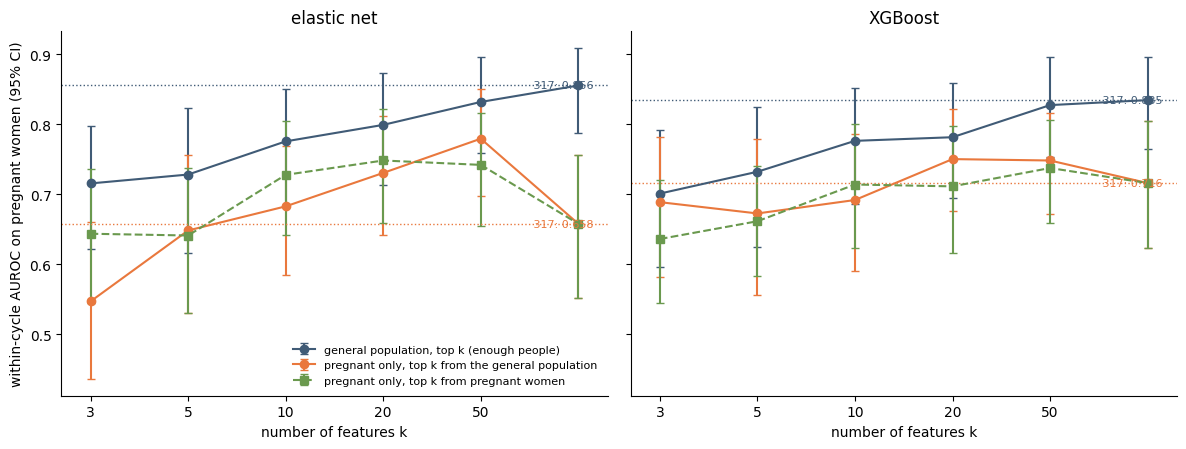

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
styles = [("general, top k", GENERAL, "#405B76", "o-", "general population, top k (enough people)"),
          ("pregnant only", GENERAL, "#E9783D", "o-", "pregnant only, top k from the general population"),
          ("pregnant only", OWN, "#6A994E", "s--", "pregnant only, top k from pregnant women")]
for ax, model in zip(axes, NAMES.values()):
    m = met[met.model == model]
    for training, selection, color, fmt, label in styles:
        d = m[(m.training == training) & (m.selection == selection)].sort_values("k")
        ax.errorbar(range(len(d)), d["within-cycle AUROC"], yerr=[d["within-cycle AUROC"] - d.lo,
                    d.hi - d["within-cycle AUROC"]], fmt=fmt, color=color, capsize=3, label=label)
    for training, color in [("general, top k", "#405B76"), ("pregnant only", "#E9783D")]:
        v = m[(m.k == 317) & (m.training == training)]["within-cycle AUROC"].iloc[0]
        ax.axhline(v, color=color, lw=1, ls=":")
        ax.text(len(KS) - 0.5, v, f" 317: {v:.3f}", color=color, va="center", fontsize=8)
    ax.set_xticks(range(len(KS)), KS)
    ax.set_xlim(-0.3, len(KS) + 0.3)
    ax.set_xlabel("number of features k")
    ax.set_title(model)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("within-cycle AUROC on pregnant women (95% CI)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plots.show()

## Conclusions

- **Fewer, stronger features help the pregnant-only model, but it does not reach the general model.** The best pregnant-only result is elastic net on the top 50 features from the general population: within-cycle AUROC 0.779 (95% CI 0.697–0.850), up from 0.658 with all 317. For XGBoost the best is 0.750 (top 20), up from 0.716. The general model is at 0.856 / 0.835.
- **Very few features are not enough even with plenty of people.** Trained on the general population, the top 3 / 5 / 10 / 20 / 50 features give 0.716 / 0.728 / 0.776 / 0.799 / 0.832 (elastic net). So the general model's 0.856 needs many features, each adding a little, and there is no small set of features that carries it.
- **This is why the gap cannot be closed by selection.** Reaching 0.83 needs about 50 features, and 50 features need more than the 28–49 positive women available: at k = 50 the pregnant-only model is 0.05 (elastic net) to 0.08 (XGBoost) below the general model with the same features. With 3–10 features the sample is less of a problem, but then the features themselves cap the AUROC below 0.78.
- **Selecting from pregnant women themselves is unstable but not worse.** The top 5 differ from fold to fold (12 different features over 7 folds; the general ranking picks the same 5 in every fold), yet at k = 10–20 it does as well as the general ranking (elastic net 0.728–0.748 against 0.683–0.731); the differences are well inside the intervals. It picks other things: family income, cotinine and smoking, urine creatinine and self-rated health, where the general ranking picks self-rated health, sleep trouble, limitations at work and memory problems. With 51 positives this difference cannot be confirmed as real.
- **In short:** feature selection moves the pregnant-only model from 0.66 to about 0.75–0.78. Matching the general model (0.856) is not possible with the 630 pregnant women in NHANES; the general model remains the better choice for them.